# 02 — Exploratory Data Analysis (EDA)

**Phase:** 2 — Exploratory Data Analysis
**Goal:** Understand the xBD dataset and derive data-driven decisions for preprocessing, splitting and training.

## Setup

In [ ]:
BRANCH = "main"

%cd /kaggle/working
!rm -rf damage-detection
!git clone -b {BRANCH} https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .

/kaggle/working
Cloning into 'damage-detection'...
remote: Enumerating objects: 114, done.
remote: Counting objects: 100% (114/114), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 114 (delta 42), reused 91 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (114/114), 964.12 KiB | 5.48 MiB/s, done.
Resolving deltas: 100% (42/42), done.
/kaggle/working/damage-detection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done


In [2]:
import json
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from src.data.xbd import list_image_ids, get_label_path, load_pair
from src.data.labels import load_label, parse_buildings, parse_metadata
from src.data.metadata import build_metadata_table

In [3]:
ROOT = Path("/kaggle/input/datasets/qianlanzz/xbd-dataset/xbd")

## 1. Analysis of JSON 

### 1.1 Label format

In [4]:
ids = list_image_ids(ROOT, "tier1")
image_id = next(i for i in ids if i.startswith("hurricane-harvey"))
print("image_id:", image_id)

with open(ROOT / "tier1" / "labels" / f"{image_id}_pre_disaster.json") as f:
    pre_label = json.load(f)
with open(ROOT / "tier1" / "labels" / f"{image_id}_post_disaster.json") as f:
    post_label = json.load(f)

print("\n Post details:")
print(json.dumps(post_label, indent=2)[:3000])

image_id: hurricane-harvey_00000000

 Post details:
{
  "features": {
    "lng_lat": [
      {
        "properties": {
          "feature_type": "building",
          "subtype": "major-damage",
          "uid": "c5549b70-5902-482a-9817-75dcc952a7be"
        },
        "wkt": "POLYGON ((-95.48923259305738 29.76927046174493, -95.4891962798546 29.76927196871654, -95.48919416981673 29.76926295380197, -95.48916308941646 29.76926518537495, -95.48915977170095 29.76924549225246, -95.48914558503374 29.76924411309804, -95.48914339358113 29.76923180711585, -95.48915555163356 29.76922746242159, -95.48915102624242 29.76919709109122, -95.48918764287016 29.76918981636998, -95.48918608914792 29.76916515113088, -95.48915496806734 29.76916573716701, -95.48915475089444 29.76911882171114, -95.48918962385561 29.76911734187421, -95.48918969164176 29.76908194515148, -95.48922791125632 29.76908122543413, -95.48923259305738 29.76927046174493))"
      },
      {
        "properties": {
          "feature_type":

### 1.2 Full format - metadata

In [5]:
# full
print("Top-level keys:", list(post_label.keys()))
print("features keys :", list(post_label["features"].keys()))

for key, value in post_label.items():
    if key != "features":
        print(f"\n{key}")
        print(json.dumps(value, indent=2))

for name, label in [("PRE", pre_label), ("POST", post_label)]:
    for fkey, flist in label["features"].items():
        print(f"\n{name} features['{fkey}']: {len(flist)} buildings")
        first = flist[0]
        print("properties:", first["properties"])
        print("wkt (first 120 chars):", first["wkt"][:120])

for fkey, flist in post_label["features"].items():
    subtypes = Counter(b["properties"].get("subtype") for b in flist)
    print(f"\nPOST subtypes in '{fkey}':", dict(subtypes))

Top-level keys: ['features', 'metadata']
features keys : ['lng_lat', 'xy']

metadata
{
  "sensor": "GEOEYE01",
  "provider_asset_type": "GEOEYE01",
  "gsd": 3.024613,
  "capture_date": "2017-08-31T17:38:50.685Z",
  "off_nadir_angle": 42.91436,
  "pan_resolution": 0.7532107,
  "sun_azimuth": 152.30608,
  "sun_elevation": 66.44999,
  "target_azimuth": 111.736275,
  "disaster": "hurricane-harvey",
  "disaster_type": "flooding",
  "catalog_id": "105001000B95E100",
  "original_width": 1024,
  "original_height": 1024,
  "width": 1024,
  "height": 1024,
  "id": "MjU3ODQ1NQ.eoj3v03PrmunSMsj5wDzr_GICTc",
  "img_name": "hurricane-harvey_00000000_post_disaster.png"
}

PRE features['lng_lat']: 30 buildings
properties: {'feature_type': 'building', 'uid': 'c5549b70-5902-482a-9817-75dcc952a7be'}
wkt (first 120 chars): POLYGON ((-95.48923259304139 29.76927046175237, -95.48919627983861 29.76927196872398, -95.48919416980074 29.769262953809

PRE features['xy']: 30 buildings
properties: {'feature_type': '

In [6]:
# test
post = load_label(get_label_path(ROOT, "tier1", image_id, "post"))
pre = load_label(get_label_path(ROOT, "tier1", image_id, "pre"))

post_buildings = parse_buildings(post)
pre_buildings = parse_buildings(pre)

print("Number of buildings:", len(post_buildings), len(pre_buildings))
print("First building:", post_buildings[0].uid, post_buildings[0].damage, round(post_buildings[0].area(), 1))
print("Damage counts (post):", Counter(b.damage for b in post_buildings))
print("Damage (pre):", pre_buildings[0].damage)
print("Metadata:", parse_metadata(post))

Number of buildings: 30 30
First building: c5549b70-5902-482a-9817-75dcc952a7be 3 587.1
Damage counts (post): Counter({2: 23, 3: 7})
Damage (pre): None
Metadata: {'disaster': 'hurricane-harvey', 'disaster_type': 'flooding', 'sensor': 'GEOEYE01', 'capture_date': '2017-08-31T17:38:50.685Z', 'off_nadir_angle': 42.91436, 'gsd': 3.024613, 'pan_resolution': 0.7532107}


## 2. Metadata table (metadata.py)

In [7]:
df = build_metadata_table(ROOT)
df.to_csv("/kaggle/working/metadata.csv", index=False)

print(df.shape)
df.head()

(11034, 21)


,image_id,folder,num_buildings,disaster,disaster_type,sensor,capture_date,off_nadir_angle,gsd,pan_resolution,...,num_no-damage,area_no-damage,num_minor-damage,area_minor-damage,num_major-damage,area_major-damage,num_destroyed,area_destroyed,num_un-classified,area_un-classified
0,guatemala-volcano_00000000,tier1,10,guatemala-volcano,volcano,WORLDVIEW03_VNIR,2018-06-22T16:55:40.000Z,21.97336,1.408524,0.351739,...,10,15205.550117,0,0.000000,0,0.0,0,0.000000,0,0.0
1,guatemala-volcano_00000001,tier1,4,guatemala-volcano,volcano,WORLDVIEW03_VNIR,2018-06-22T16:55:40.000Z,21.97336,1.408524,0.351739,...,0,0.000000,4,2390.783491,0,0.0,0,0.000000,0,0.0
2,guatemala-volcano_00000002,tier1,1,guatemala-volcano,volcano,WORLDVIEW03_VNIR,2018-06-22T16:55:40.000Z,21.97336,1.408524,0.351739,...,0,0.000000,0,0.000000,0,0.0,1,2395.839914,0,0.0
3,guatemala-volcano_00000006,tier1,97,guatemala-volcano,volcano,WORLDVIEW03_VNIR,2018-06-22T16:55:40.000Z,21.97336,1.408524,0.351739,...,97,42862.625331,0,0.000000,0,0.0,0,0.000000,0,0.0
4,guatemala-volcano_00000007,tier1,9,guatemala-volcano,volcano,WORLDVIEW03_VNIR,2018-06-22T16:55:40.000Z,21.97336,1.408524,0.351739,...,9,9138.331755,0,0.000000,0,0.0,0,0.000000,0,0.0


### 2.1 Check the table

In [8]:
print(df["folder"].value_counts())

folder
tier3    6369
tier1    2799
test      933
hold      933
Name: count, dtype: int64


In [9]:
# Is the number of buildings the same in pre and post?
mismatch = df[df["num_buildings"] != df["num_buildings_pre"]]
print("Pairs with different pre/post building counts:", len(mismatch))

Pairs with different pre/post building counts: 0


In [10]:
# are there any missing values?
missing = df.isna().sum()
print(missing[missing > 0])

Series([], dtype: int64)


**checks**
- 11,034 pairs (tier1 2,799 · tier3 6,369 · test 933 · hold 933), matching Phase 0
- Pre and post labels contain the same number of buildings in every pair
- No missing values in any column.

## 3. EDA

## 3.1 Events and disaster types

In [11]:
events = df.groupby(["disaster_type", "disaster"]).size().sort_values(ascending=False)
print(events)

print("\nNumber of events:", df["disaster"].nunique())

print(df["disaster_type"].value_counts())

disaster_type  disaster           
fire           portugal-wildfire      1869
               pinery-bushfire        1845
               socal-fire             1403
               woolsey-fire            878
flooding       nepal-flooding          619
wind           hurricane-michael       550
flooding       hurricane-florence      546
               hurricane-harvey        522
               midwest-flooding        445
wind           hurricane-matthew       405
fire           santa-rosa-wildfire     377
wind           tuscaloosa-tornado      343
volcano        lower-puna-volcano      291
wind           moore-tornado           227
tsunami        palu-tsunami            196
earthquake     mexico-earthquake       193
wind           joplin-tornado          149
tsunami        sunda-tsunami           148
volcano        guatemala-volcano        28
dtype: int64

Number of events: 19
disaster_type
fire          6372
flooding      2132
wind          1674
tsunami        344
volcano        319
eart

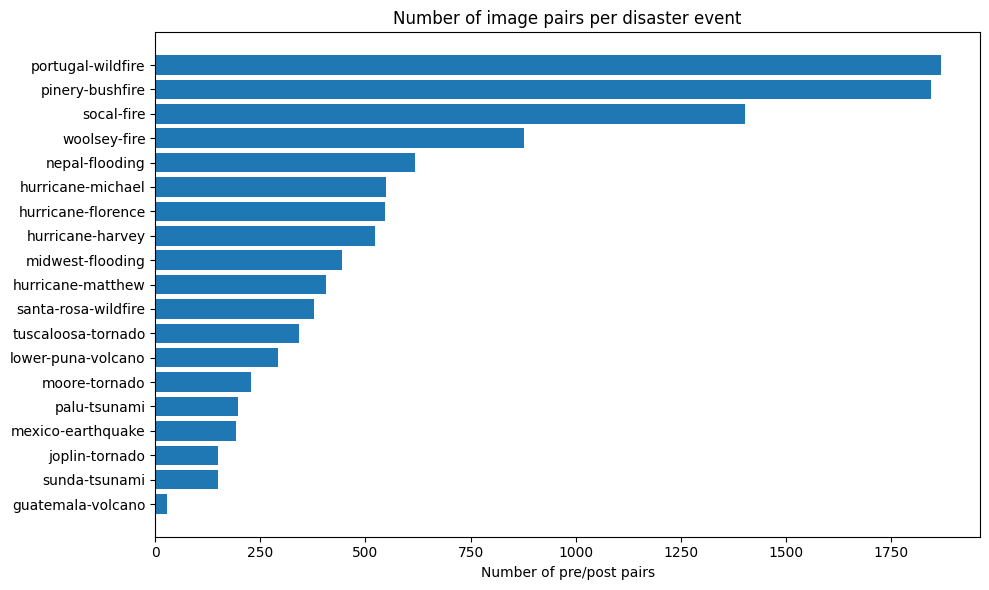

In [12]:
counts = df["disaster"].value_counts()

plt.figure(figsize=(10, 6))
plt.barh(counts.index, counts.values)
plt.gca().invert_yaxis()
plt.xlabel("Number of pre/post pairs")
plt.title("Number of image pairs per disaster event")
plt.tight_layout()
plt.savefig("/kaggle/working/eda_pairs_per_event.png", dpi=150)
plt.show()


Number of disaster types: 6


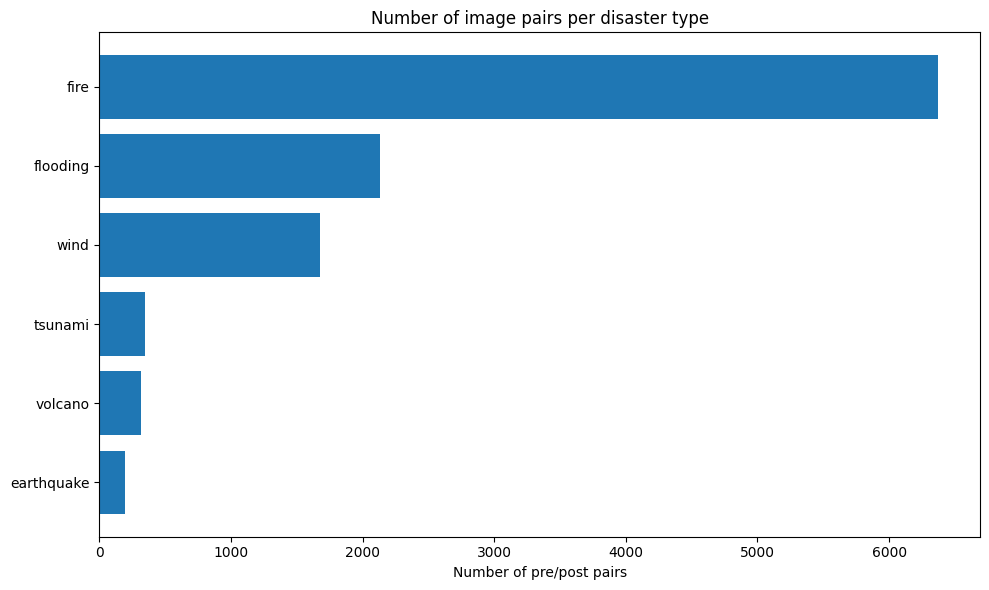

In [13]:
print("\nNumber of disaster types:", df["disaster_type"].nunique())

counts = df["disaster_type"].value_counts()

plt.figure(figsize=(10, 6))
plt.barh(counts.index, counts.values)
plt.gca().invert_yaxis()
plt.xlabel("Number of pre/post pairs")
plt.title("Number of image pairs per disaster type")
plt.tight_layout()
plt.savefig("/kaggle/working/eda_pairs_per_disaster_type.png", dpi=150)
plt.show()

## 3.2 Damage class distribution

In [14]:
damage_columns = [
    "num_no-damage",
    "num_minor-damage",
    "num_major-damage",
    "num_destroyed",
    "num_un-classified"
]

damage_counts = df[damage_columns].sum()

num_buildings = damage_counts.sum()

damage_percent = damage_counts / num_buildings * 100

print("Total buildings: ", num_buildings)
print()
print(damage_counts)
print()
print(damage_percent)

Total buildings:  425368

num_no-damage        313033
num_minor-damage      36860
num_major-damage      29904
num_destroyed         31560
num_un-classified     14011
dtype: int64

num_no-damage        73.591102
num_minor-damage      8.665438
num_major-damage      7.030148
num_destroyed         7.419458
num_un-classified     3.293854
dtype: float64


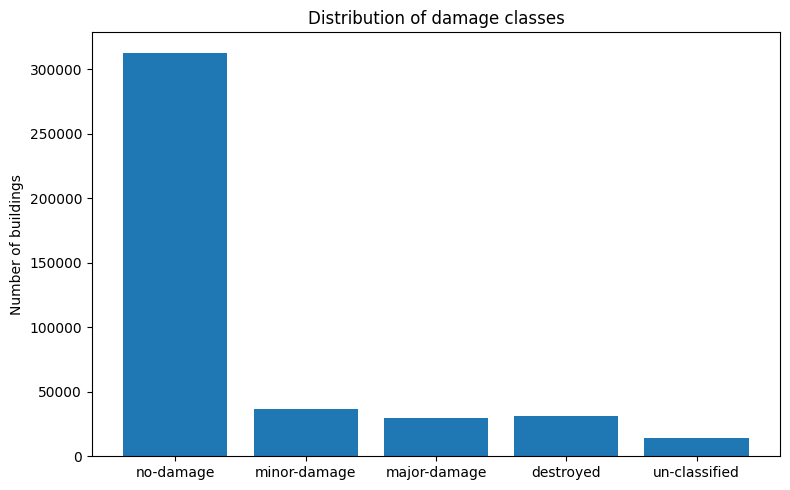

In [15]:
labels = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]

plt.figure(figsize=(8, 5))
plt.bar(labels, damage_counts.values)
plt.ylabel("Number of buildings")
plt.title("Distribution of damage classes")
plt.tight_layout()
plt.savefig("/kaggle/working/eda_damage_classes.png", dpi=150)
plt.show()

### 3.2 Damage classes per disaster type

               no-damage  minor-damage  major-damage  destroyed  \
disaster_type                                                     
wind               64927         25737          7556      10704   
flooding           71148         10122         20241       1596   
fire               61992           704           726      11338   
tsunami            60874             1          1278       7382   
earthquake         51084           221            54          3   
volcano             3008            75            49        537   

               un-classified   total  
disaster_type                         
wind                    3857  112781  
flooding                3557  106664  
fire                    2553   77313  
tsunami                 3201   72736  
earthquake               111   51473  
volcano                  732    4401  
               no-damage  minor-damage  major-damage  destroyed  un-classified
disaster_type                                                           

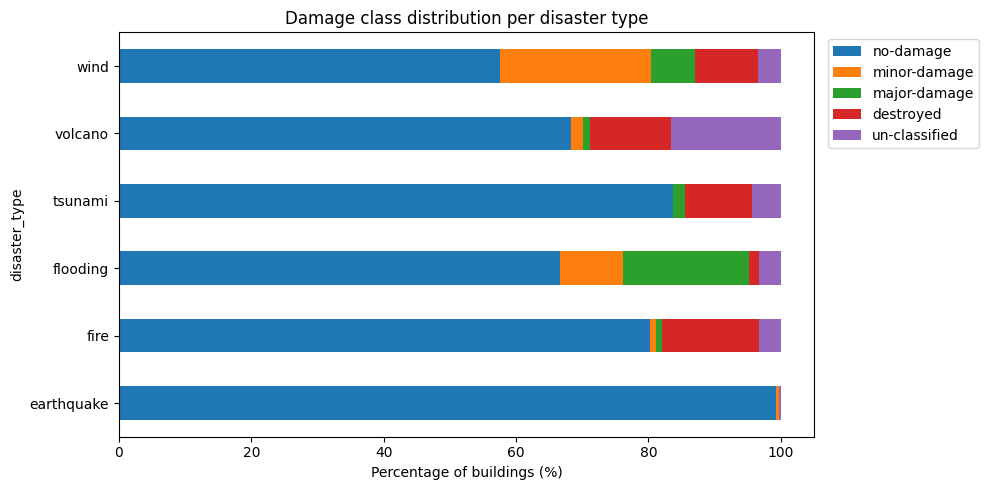

In [16]:
damage_columns = ["num_no-damage", "num_minor-damage", "num_major-damage", "num_destroyed", "num_un-classified"]
labels = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]

damage_by_type = df.groupby("disaster_type")[damage_columns].sum()
damage_by_type.columns = labels
damage_by_type["total"] = damage_by_type.sum(axis=1)

print(damage_by_type.sort_values("total", ascending=False))

damage_pct = damage_by_type[labels].div(damage_by_type["total"], axis=0) * 100
print(damage_pct.round(1))

damage_pct.plot(kind="barh", stacked=True, figsize=(10, 5))
plt.xlabel("Percentage of buildings (%)")
plt.title("Damage class distribution per disaster type")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("/kaggle/working/eda_damage_per_type.png", dpi=150)
plt.show()

**Findings**

- **Earthquake data contains almost no damage:** the only earthquake in xBD (Mexico City, 2017) has 51,473 buildings, of which **99.2% are undamaged** and only **3 are destroyed**. The model therefore cannot learn what earthquake damage.
  - Earthquake results in Phase 7 can only be interpreted for localization and the no-damage class.
  - This strongly motivates fine-tuning on Türkiye earthquake data.
- Each damage class is dominated by one disaster type: 70% of minor-damage buildings come from wind events and 68% of major-damage buildings from flooding events; destroyed buildings mostly come from fire, wind and tsunami. The model may therefore learn disaster-specific visual cues instead of the damage itself. This will be investigated with Grad-CAM.


### 3.3 Pixel ares

In [17]:
area_columns = [
    "area_no-damage", 
    "area_minor-damage", 
    "area_major-damage", 
    "area_destroyed", 
    "area_un-classified"
]

area_counts = df[area_columns].sum()

total_pixels = len(df) * 1024 * 1024

building_pixels = area_counts.sum()
background_pixels = total_pixels - building_pixels

print("Background:", round(background_pixels / total_pixels * 100, 2), "%")
print()
print((area_counts / total_pixels * 100).round(2))

Background: 96.65 %

area_no-damage        2.50
area_minor-damage     0.29
area_major-damage     0.31
area_destroyed        0.19
area_un-classified    0.05
dtype: float64


**Findings**

- **Number of buildings:** The post-disaster labels contain **425,368 buildings**. The xBD paper reports 850,736 building annotations (Gupta et al., 2019), because each building is annotated in both the pre- and post-disaster image (425,368 × 2 = 850,736).
- **Class imbalance (buildings):** **73.6%** of the buildings are undamaged. This matches the 73.6% reported by Weber & Kané (2020).
- **Class imbalance (pixels):** **96.65%** of all pixels are background, and buildings cover only 3.35% of the images.
- **Consequences:**
  - Pixel accuracy is not a meaningful metric: a model that predicts background everywhere would reach 96.65% accuracy without detecting a single building. We therefore use the F1-based xView2 score.
  - The loss function must handle this imbalance, which motivates **Focal Loss + Dice Loss**.

### 3.4 Buildings per image

count    11034.000000
mean        38.550662
std         89.936934
min          0.000000
25%          0.000000
50%          6.000000
75%         35.000000
max       1843.000000
Name: num_buildings, dtype: float64
Images without buildings: 3858
Ratio: 35.0 %
disaster_type
fire        3448
flooding     152
volcano      109
wind         103
tsunami       46
Name: count, dtype: int64


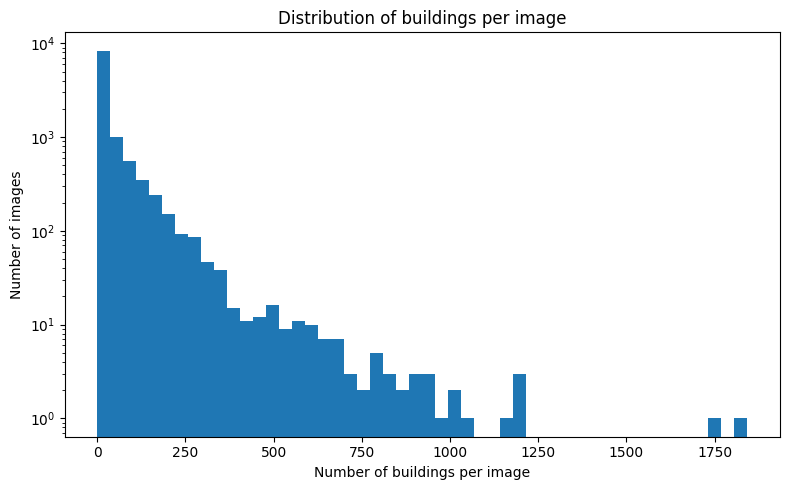

In [18]:
print(df["num_buildings"].describe())

empty = df["num_buildings"] == 0
print("Images without buildings:", empty.sum())
print("Ratio:", round(empty.mean() * 100, 1), "%")

print(df[empty]["disaster_type"].value_counts())

plt.figure(figsize=(8, 5))
plt.hist(df["num_buildings"], bins=50)
plt.xlabel("Number of buildings per image")
plt.ylabel("Number of images")
plt.title("Distribution of buildings per image")
plt.yscale("log")
plt.tight_layout()
plt.savefig("/kaggle/working/eda_buildings_per_image.png", dpi=150)
plt.show()

**Findings**

- **35.0%** of the images (3,858 of 11,034) contain no buildings at all.

## 4. Visual examples

In [19]:
# The image with the most damaged buildings from each disaster type
df["num_damaged"] = df["num_minor-damage"] + df["num_major-damage"] + df["num_destroyed"]

best_rows = df.groupby("disaster_type")["num_damaged"].idxmax()
examples = df.loc[best_rows]

print(examples[["disaster_type", "image_id", "num_buildings", "num_damaged"]])

      disaster_type                      image_id  num_buildings  num_damaged
9571     earthquake    mexico-earthquake_00000069            333           28
10717          fire  santa-rosa-wildfire_00000157            271          271
10252      flooding     hurricane-harvey_00000149            332          332
1707        tsunami         palu-tsunami_00000118           1843         1549
3191        volcano   lower-puna-volcano_00000243             74           74
746            wind    hurricane-matthew_00000156            641          621


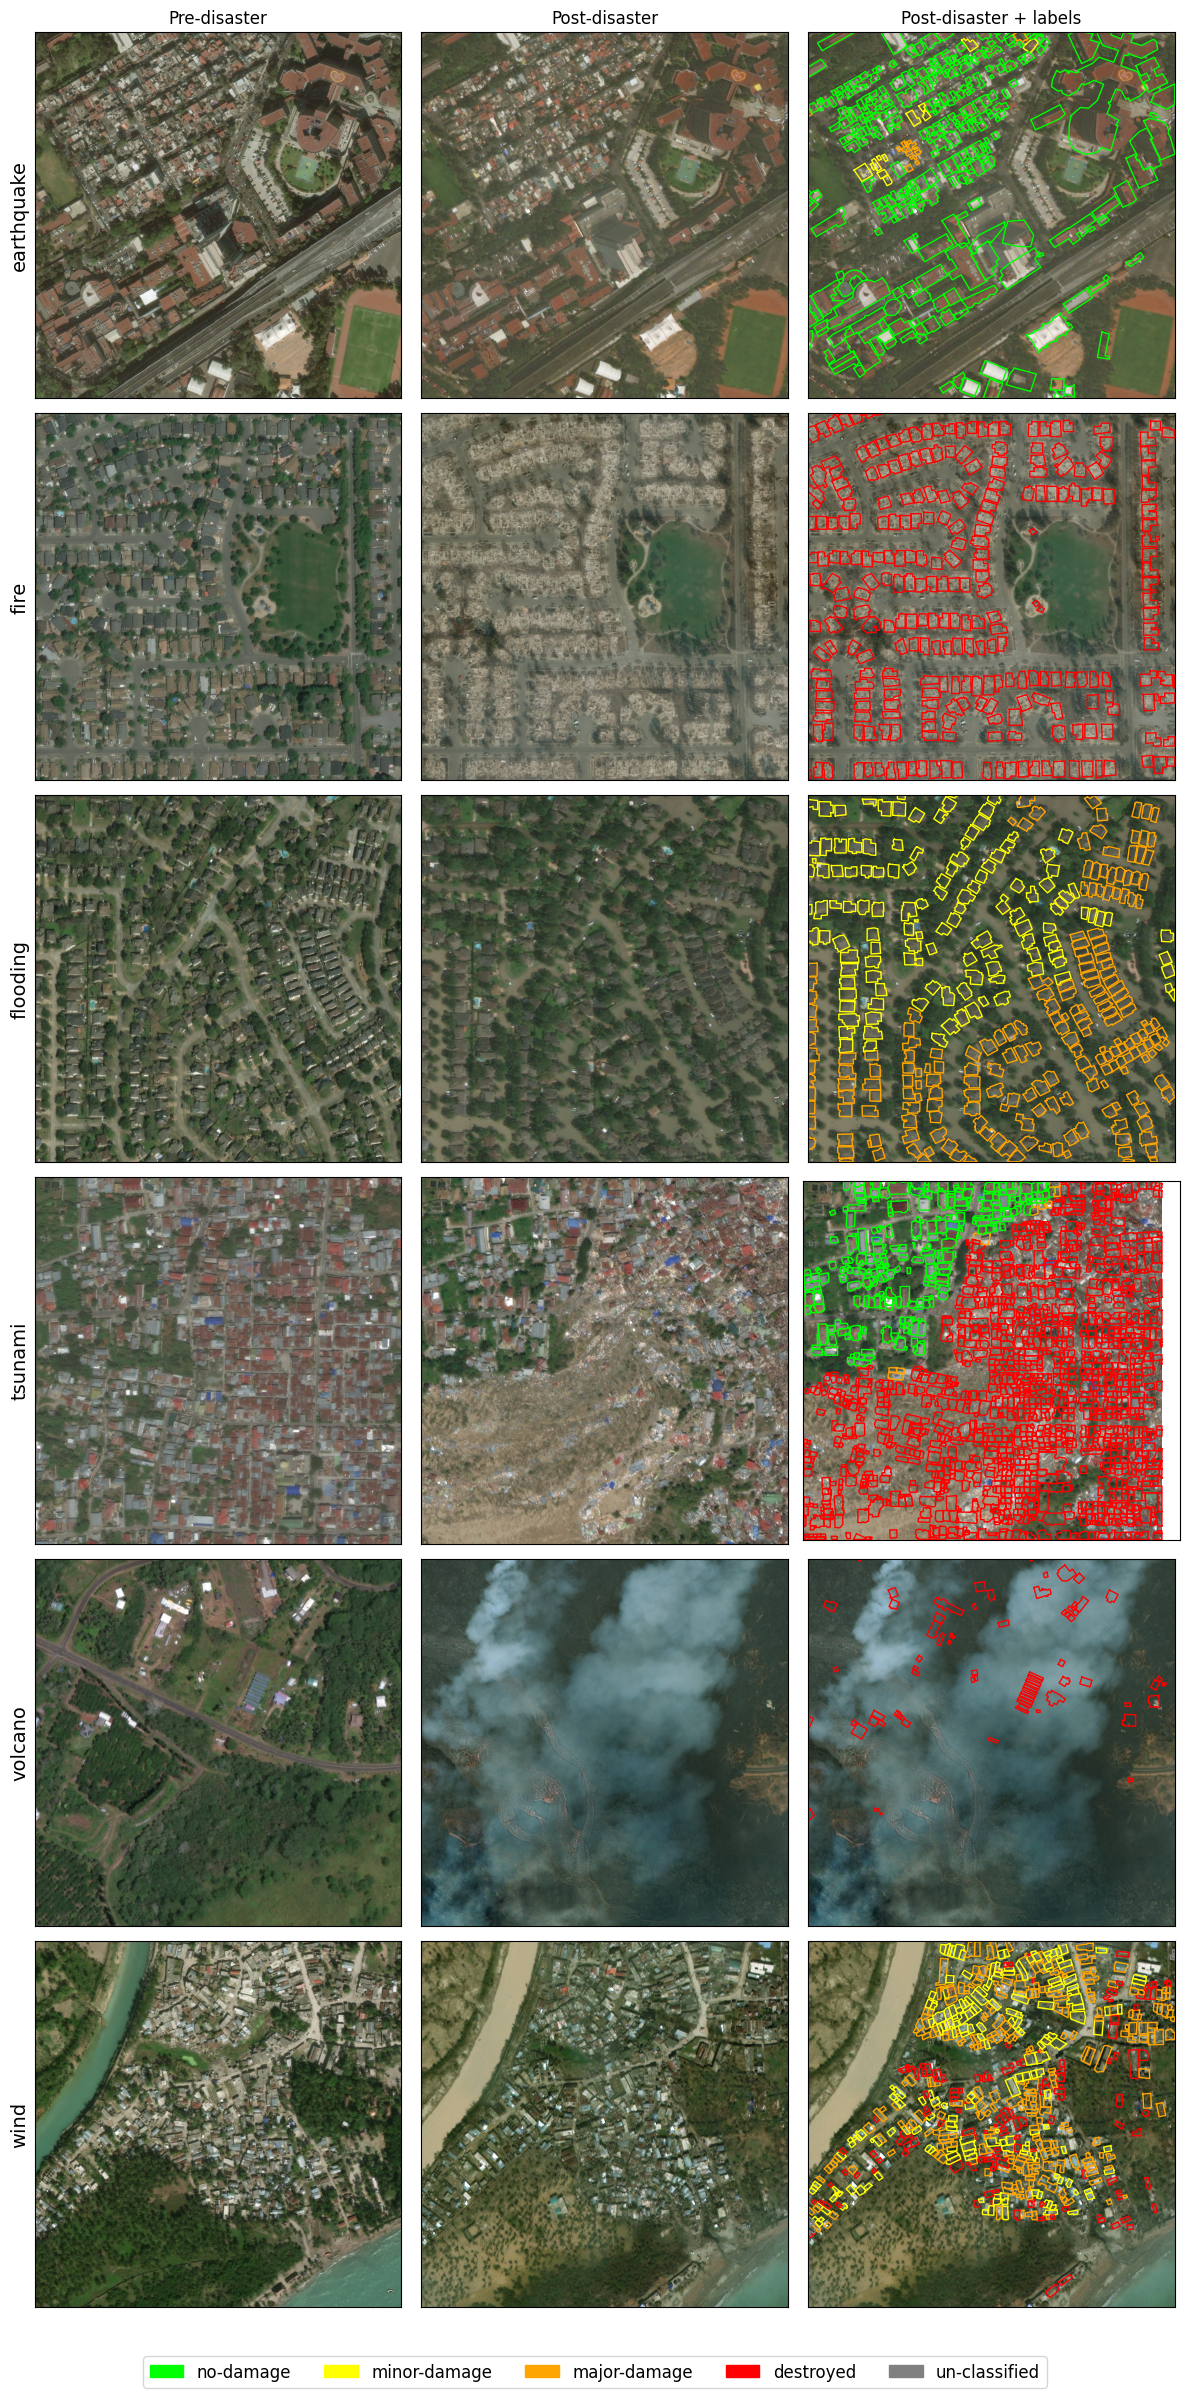

In [20]:
COLORS = {1: "lime", 2: "yellow", 3: "orange", 4: "red", 255: "gray"}

fig, axes = plt.subplots(len(examples), 3, figsize=(12, 4 * len(examples)))

for i, (_, row) in enumerate(examples.iterrows()):
    pre, post = load_pair(ROOT, row["folder"], row["image_id"])
    label = load_label(get_label_path(ROOT, row["folder"], row["image_id"], "post"))

    axes[i, 0].imshow(pre)
    axes[i, 1].imshow(post)
    axes[i, 2].imshow(post)

    for b in parse_buildings(label):
        for part in getattr(b.polygon, "geoms", [b.polygon]):
            xs, ys = part.exterior.xy
            axes[i, 2].plot(xs, ys, color=COLORS[b.damage], linewidth=1)

    axes[i, 0].set_ylabel(row["disaster_type"], fontsize=14)
    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])

axes[0, 0].set_title("Pre-disaster")
axes[0, 1].set_title("Post-disaster")
axes[0, 2].set_title("Post-disaster + labels")

legend = [mpatches.Patch(color=c, label=name) for name, c in
          zip(["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"], COLORS.values())]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("/kaggle/working/eda_examples.png", dpi=120)
plt.show()

## Summary and Decision

| Finding | Decision | Phase |
|---|---|---|
| 11,034 pairs from 19 events | Split stratified by disaster event, so that every event is represented in train/val/test | 3 |
| Pre and post labels contain the same buildings in every pair | Draw masks from the post-disaster labels  | 3 |
| Buildings are small relative to the 1024×1024 images (Weber & Kané, 2020) | Split images into four 512×512 tiles instead of resizing | 3 |
| 73.6% of buildings are undamaged; 96.65% of pixels are background | Use Focal Loss + Dice Loss| 4 |
| Destroyed pixels are ~500× rarer than background | Focal Loss class weights must be smoothed | 4 |
| Background dominates the Dice score | Exclude background from the Dice average | 4 |
| 35% of images contain no buildings | Keep only a fraction of empty images during training | 4 |
| Un-classified buildings 3.3% | Ignore them in the loss (index 255) | 3–4 |
| Earthquake (Mexico City) has 99.2% undamaged buildings and only 3 destroyed | Interpret earthquake results only for localization and no-damage | 6–7 |
| Each damage class is dominated by one disaster type (minor ← wind, major ← flooding) | Check with Grad-CAM whether the model looks at the building or at disaster cues (shortcut learning) | 8 |
| xBD contains almost no earthquake damage | Strong motivation for fine-tuning on Türkiye earthquake data | 9 |
